DENSITY BASED CLUSTERING 

we have to set an epsilon value corresponding to the radius (ogni punto ha attorno a se un raggio di ricerca)

[identifichiamo come MinPoints il numero di punti necessario per far considerare "densa" un'area di punti] 

core point (punti in cui all'interno del suo raggio epsilon ci sono almeno MinPoints incluso il punto stesso)

border point (punto che ha meno di MinPoints nel suo raggio epsilon ma è nel raggio di un core point)

noise point (un punto è noise point se non è ne un border point ne un core point) [quindi se non è raggiungibile da core point]


In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [10]:
import sklearn
# scaling and normalization 
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# kmeans, dbscan, hierarchical(sklearn)
from sklearn.cluster import DBSCAN
# evaluation 
from sklearn.metrics import silhouette_score
# distance matrix 
from scipy.spatial.distance import pdist,squareform
# hierarchical (scipy)
from scipy.cluster.hierarchy import linkage,dendrogram,fcluster

from sklearn.neighbors import NearestNeighbors

In [5]:
df = pd.read_csv('../data/processed/board_games_clean.csv')

features = [
    'YearPublished', 
    'ComWeight', 
    'MinPlayers', 
    'MaxPlayers', 
    'ComAgeRec', 
    'NumOwned', 
    'ComMaxPlaytime',
    'ComMinPlaytime', 
    'Rating'
]

df_train = df[features]

In [78]:
scaler = StandardScaler()

X = scaler.fit_transform(df_train)



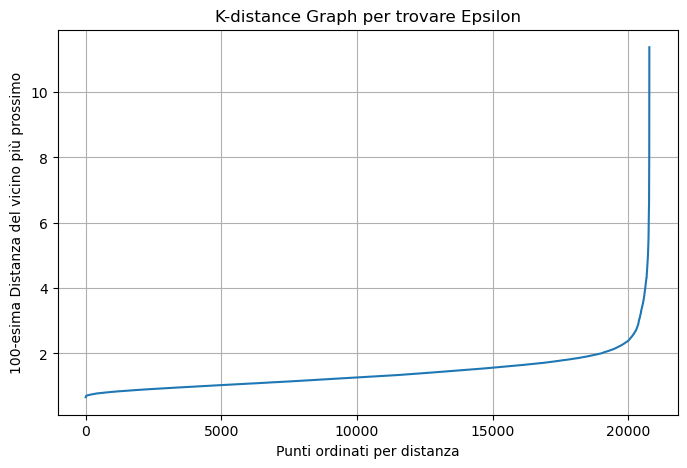

In [68]:
# scelta del minsample ed epsilon

# applichiamo la seguente formula 

min_pts = 100

# invece per scegliere epsilon applichiamo l'elbow method 


# Supponiamo che X sia il tuo dataset scalato
# Scegliamo k uguale al MinPts desiderato (es. 5)
k = 100
neigh = NearestNeighbors(n_neighbors=k)
nbrs = neigh.fit(X)
distances, indices = nbrs.kneighbors(X)

# Ordiniamo le distanze (prendiamo la colonna del k-esimo vicino)
distances = np.sort(distances[:, k-1], axis=0)

# Plot
plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('K-distance Graph per trovare Epsilon')
plt.xlabel('Punti ordinati per distanza')
plt.ylabel(f'{k}-esima Distanza del vicino più prossimo')
plt.grid(True)
plt.show()


In [74]:
db = DBSCAN(eps= 1.4, min_samples= min_pts)

clusters = db.fit_predict(X)

n_clusters_ = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise_ = list(clusters).count(-1)

print(f'Numero di cluster stimati: {n_clusters_}')
print(f'Numero di punti di rumore: {n_noise_}')

# possiamo notare che spostando il valore eps da 1.3 ad 1.4 il numero di cluster passa da 12 a 4 (i noise point si alzano  di 300 ma comunque sono un numero accettabile)

Numero di cluster stimati: 3
Numero di punti di rumore: 3074


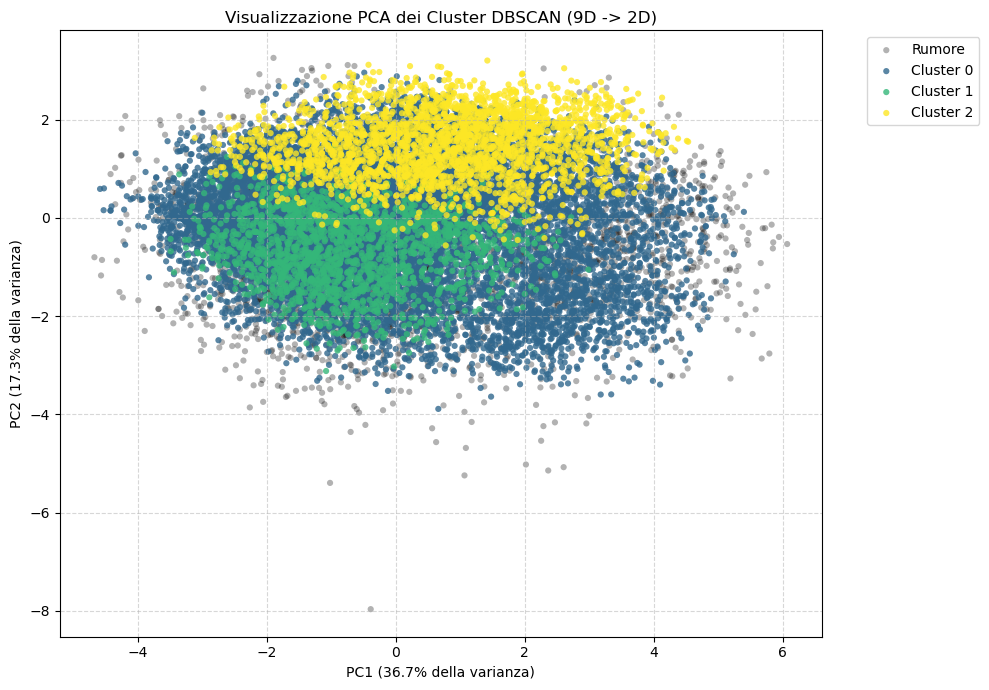

In [75]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
# Ora plotta X_pca invece di X originale
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# 1. Inizializziamo la PCA per ridurre a 2 dimensioni
pca = PCA(n_components=2)

# 2. Trasformiamo i dati a 9 dimensioni (X_scaled) in 2 dimensioni
# Sostituisci 'X_scaled' con il nome della tua variabile dei dati
X_pca = pca.fit_transform(X)

# 3. Creazione del plot
plt.figure(figsize=(10, 7))

# Otteniamo le etichette uniche (i tuoi cluster + il rumore -1)
unique_labels = np.unique(clusters)

# Definiamo una palette di colori
colors = plt.get_cmap('viridis', len(unique_labels))

for i, label in enumerate(unique_labels):
    # Se il punto è rumore (-1), lo coloriamo di nero
    if label == -1:
        color = 'black'
        label_name = 'Rumore'
        alpha = 0.3 # Rendiamo il rumore un po' trasparente per vedere meglio i cluster
    else:
        color = colors(i)
        label_name = f'Cluster {label}'
        alpha = 0.8

    # Selezioniamo solo i punti appartenenti al cluster corrente
    mask = (clusters == label)
    
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                c=color, label=label_name, 
                alpha=alpha, edgecolors='none', s=20)

# 4. Abbellimento del grafico
plt.title('Visualizzazione PCA dei Cluster DBSCAN (9D -> 2D)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} della varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} della varianza)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

In [76]:
from sklearn.metrics import silhouette_score
score = silhouette_score(X, clusters)
print(f"Silhouette Score: {score}") #  0.016136972872526655 con minpts = 18 epsilon = 1.4 

Silhouette Score: -0.01132105037604109



Sovrapposizione Massiccia: I cluster (blu, giallo e verde) sono completamente mescolati tra loro. In un buon clustering, dovresti vedere delle separazioni nette o almeno delle zone di densità distinte. Qui sembrano un'unica grande massa informe "tagliata" a fette.

Effetto "Zuppa di punti": Il rumore (punti grigi) è sparso ovunque all'interno dei cluster. Questo indica che l'algoritmo non sta distinguendo tra zone ad alta densità e zone isolate, ma sta etichettando i punti in modo quasi casuale.

Mancanza di struttura: I dati sembrano avere una distribuzione molto densa e uniforme (un grande blocco quadrato). DBSCAN eccelle quando ci sono "vuoti" tra i gruppi; se i dati sono un unico blocco continuo, DBSCAN proverà a dividerlo forzatamente o a unirlo tutto in base a Epsilon.


SECONDO TENTATIVO CON DIVERSI ATTRIBUTI 

con le stesse feature usate per il k-means il db scan fornisce risultati molto scandenti, andiamo quindi a farne un'altro su un set di feature più adatto:


In [83]:
db_feature = ["Rating", "ComWeight", "MaxPlayers","ComAgeRec"]

df_db_train = df[db_feature]

In [ ]:
Y = scaler.fit_transform(df_db_train)


In [122]:
db_2 = DBSCAN(eps= 0.8, min_samples= 47)

clusters_2 = db_2.fit_predict(Y)

n_clusters_ = len(set(clusters_2)) - (1 if -1 in clusters_2 else 0)
n_noise_ = list(clusters_2).count(-1)

print(f'Numero di cluster stimati: {n_clusters_}')
print(f'Numero di punti di rumore: {n_noise_}')

Numero di cluster stimati: 3
Numero di punti di rumore: 439


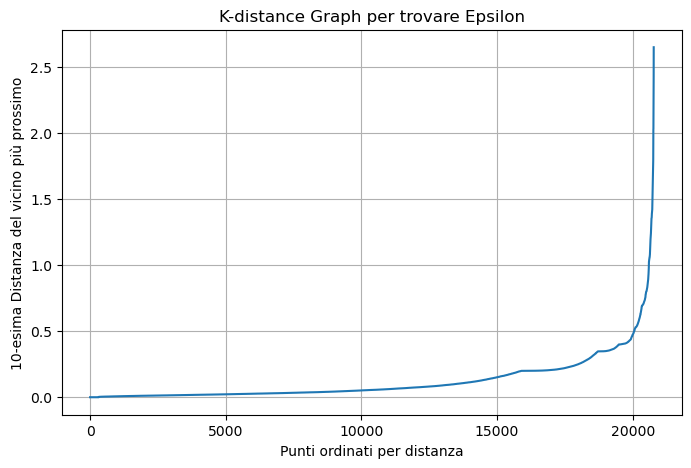

In [113]:
k = 10
neigh = NearestNeighbors(n_neighbors=k)
nbrs = neigh.fit(Y)
distances, indices = nbrs.kneighbors(Y)

# Ordiniamo le distanze (prendiamo la colonna del k-esimo vicino)
distances = np.sort(distances[:, k-1], axis=0)

# Plot
plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('K-distance Graph per trovare Epsilon')
plt.xlabel('Punti ordinati per distanza')
plt.ylabel(f'{k}-esima Distanza del vicino più prossimo')
plt.grid(True)
plt.show()

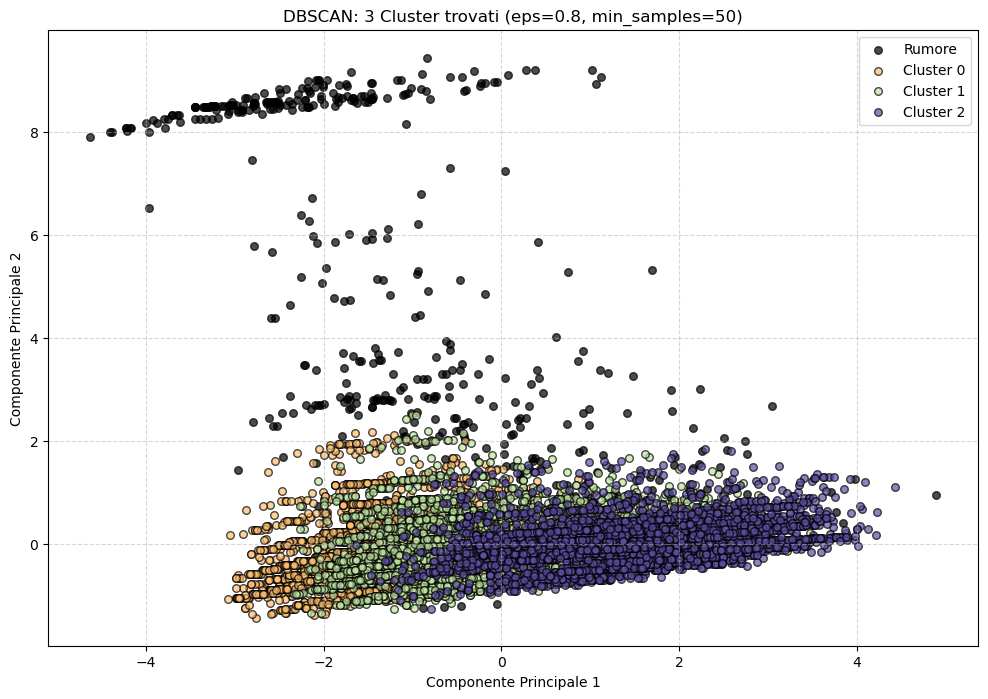

In [123]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# 1. Riduciamo le dimensioni a 2 per il plot
pca = PCA(n_components=2)
Y_pca = pca.fit_transform(Y) # Usiamo Y che è il dataset che hai passato al fit_predict

# 2. Prepariamo il grafico
plt.figure(figsize=(12, 8))

# Identifichiamo i cluster unici
unique_labels = np.unique(clusters_2)
# Creiamo una mappa di colori (escludendo il nero per il rumore)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Colore nero per il rumore (Noise points)
        col = [0, 0, 0, 1]
        label_name = "Rumore"
    else:
        label_name = f"Cluster {k}"

    class_member_mask = (clusters_2 == k)
    
    # Plot dei punti
    plt.scatter(Y_pca[class_member_mask, 0], Y_pca[class_member_mask, 1], 
                c=[col], label=label_name,
                edgecolor='k', s=30, alpha=0.7)

plt.title(f'DBSCAN: {n_clusters_} Cluster trovati (eps=0.8, min_samples=50)')
plt.xlabel('Componente Principale 1')
plt.ylabel('Componente Principale 2')
plt.legend(loc='best', bbox_to_anchor=(1, 1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [124]:
score = silhouette_score(Y, clusters)
print(f"Silhouette Score: {score}") #  0.016136972872526655 con minpts = 18 epsilon = 1.4 

Silhouette Score: 0.7116003545150128
